# Matemáticas para Inteligencia Artificial — Práctica de Python
## Ejercicio 1 · Descenso del gradiente (dos variables)

**Enunciado del profesor**

$$f(x)=\tfrac12 x^T A x-b^T x,\qquad
A=\begin{bmatrix}4&0\\0&10\end{bmatrix},\quad
b=\begin{bmatrix}-8\\10\end{bmatrix}.$$

Se utilizará $x_0=(0,0)$ y $\gamma=0.15$.

**Objetivos:** reproducir en Python las tres iteraciones $x_1,x_2,x_3$ que se desarrollan a mano; continuar hasta que $\|\nabla f(x)\|<10^{-6}$; reportar el mínimo y graficar $f(x_i)$.


### 1. Ecuación y gradiente

El desarrollo matricial da

$$f(x_1,x_2)=2x_1^2+5x_2^2+8x_1-10x_2.$$

El gradiente obtenido por derivadas parciales es

$$\nabla f(x)=\begin{bmatrix}4x_1+8\\10x_2-10\end{bmatrix}.$$

También se calcula con la forma matricial $\nabla f(x)=Ax-b$ (porque $A$ es simétrica). Se empleará esa fórmula en el programa.


In [1]:
# Librerías: NumPy para vectores/matrices; pandas para tabla; Matplotlib para gráfica.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

A = np.array([[4.0, 0.0],
              [0.0, 10.0]])
b = np.array([-8.0, 10.0])
gamma = 0.15
x0 = np.array([0.0, 0.0])

print("Matriz A:\n", A)
print("Vector b:", b)
print("Punto inicial:", x0)
print("Tasa de aprendizaje:", gamma)

Matriz A:
 [[ 4.  0.]
 [ 0. 10.]]
Vector b: [-8. 10.]
Punto inicial: [0. 0.]
Tasa de aprendizaje: 0.15


### 2. Programación de la función y el gradiente

- `x @ A @ x` multiplica el vector transpuesto por la matriz y el vector columna.
- `b @ x` hace el producto fila por columna.
- `A @ x - b` calcula el gradiente sin derivar manualmente cada iteración.

**Nota:** En NumPy, un arreglo de una dimensión funciona como vector para estos productos; por eso no es necesario escribir `.T` en este ejemplo.


In [2]:
def funcion(x):
    """f(x) = (1/2) xᵀ A x - bᵀ x."""
    return 0.5 * (x @ A @ x) - (b @ x)


def gradiente(x):
    """∇f(x) = A x - b."""
    return A @ x - b


# Comprobación con el primer punto de la tabla:
print("f(x0) =", funcion(x0))
print("∇f(x0) =", gradiente(x0))
assert np.isclose(funcion(x0), 0)
assert np.allclose(gradiente(x0), [8, -10])

f(x0) = 0.0
∇f(x0) = [  8. -10.]


### 3. Las tres iteraciones solicitadas a mano

Se utiliza la fórmula del profesor:

$$x_{i+1}=x_i-\gamma\nabla f(x_i).$$

La **fila 0** es el estado inicial. A partir de ella se actualiza el punto para llegar a $x_1$, $x_2$ y $x_3$. Se guardan cuatro filas en total para comparar con el cuaderno.


In [3]:
x = x0.copy()
filas = []

for i in range(4):
    g = gradiente(x)
    valor = funcion(x)
    filas.append({"i": i, "x1": x[0], "x2": x[1],
                  "gradiente_1": g[0], "gradiente_2": g[1], "f(x)": valor})

    if i < 3:
        x = x - gamma * g  # Fórmula de descenso del gradiente

tabla = pd.DataFrame(filas)
display(tabla.round(4))

,i,x1,x2,gradiente_1,gradiente_2,f(x)
0,0,0.000,0.000,8.000,-10.00,0.0000
1,1,-1.200,1.500,3.200,5.00,-10.4700
2,2,-1.680,0.750,1.280,-2.50,-12.4827
3,3,-1.872,1.125,0.512,1.25,-12.8891


**Comprobación de las tres iteraciones:**

| Iteración | $x_i$ | $\nabla f(x_i)$ | $f(x_i)$ |
|---:|---|---|---:|
| 0 | $(0,0)$ | $(8,-10)$ | $0$ |
| 1 | $(-1.2,1.5)$ | $(3.2,5)$ | $-10.47$ |
| 2 | $(-1.68,0.75)$ | $(1.28,-2.5)$ | $-12.4827$ |
| 3 | $(-1.872,1.125)$ | $(0.512,1.25)$ | $-12.889107$ |


In [4]:
# Verificación automática: coincide con las iteraciones resueltas a mano.
assert np.allclose(tabla[["x1", "x2"]].to_numpy(),
                   [[0, 0], [-1.2, 1.5], [-1.68, 0.75], [-1.872, 1.125]])
print("Las tres iteraciones coinciden con las calculadas a mano.")

Las tres iteraciones coinciden con las calculadas a mano.


### 4. Continuar hasta alcanzar el mínimo

La tarea pide seguir iterando en Python hasta que la magnitud del gradiente sea menor que $10^{-6}$:

$$\|\nabla f(x_i)\|<10^{-6}.$$

La norma mide qué tan cerca está el **vector gradiente** de cero. Se utiliza `np.linalg.norm`.


In [5]:
tolerancia = 1e-6
max_iteraciones = 10000
x = x0.copy()
historial = []
convergio = False

for i in range(max_iteraciones + 1):
    g = gradiente(x)
    fx = funcion(x)
    norma = np.linalg.norm(g)
    historial.append((i, x[0], x[1], fx, norma))

    if norma < tolerancia:
        convergio = True
        break

    x = x - gamma * g

historial = pd.DataFrame(historial, columns=["iteracion", "x1", "x2", "f(x)", "norma_gradiente"])
print("¿Convergió?:", convergio)
print("Iteraciones:", i)
print("Punto mínimo aproximado:", np.round(x, 8))
print("Valor de la función:", round(float(funcion(x)), 8))
print("Gradiente final:", gradiente(x))
print("Norma final:", norma)

assert convergio
assert i == 24
assert np.allclose(x, [-2, 1], atol=1e-6)
assert np.isclose(funcion(x), -13, atol=1e-8)

¿Convergió?: True
Iteraciones: 24
Punto mínimo aproximado: [-2.          0.99999994]
Valor de la función: -13.0
Gradiente final: [ 2.25179964e-09 -5.96046448e-07]
Norma final: 5.960507012676431e-07


### 5. Gráfica de convergencia

Cada punto representa el valor $f(x_i)$ de una iteración. La gráfica debe descender hacia $-13$.


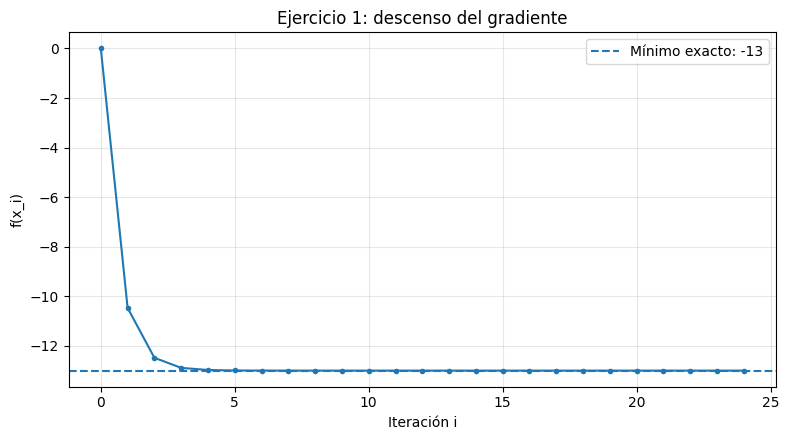

In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(historial["iteracion"], historial["f(x)"], marker="o", markersize=3)
plt.axhline(-13, linestyle="--", label="Mínimo exacto: -13")
plt.title("Ejercicio 1: descenso del gradiente")
plt.xlabel("Iteración i")
plt.ylabel("f(x_i)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6. Conclusión para la entrega

Con el punto inicial $x_0=(0,0)$ y la tasa de aprendizaje $\gamma=0.15$, las tres primeras actualizaciones en Python coinciden con las calculadas manualmente. El algoritmo cumple $\|\nabla f(x_i)\|<10^{-6}$ después de **24 iteraciones** y alcanza el mínimo aproximado $x^*\approx(-2,1)$, con $f(x^*)\approx-13$. La gráfica muestra la disminución de la función hacia ese mínimo.
